**中心极限定理**

中心极限定理（Central Limit Theorem，简称 CLT）是统计学中最神奇也最重要的定理之一。简单来说：**无论总体数据原本服从什么分布（哪怕是严重偏斜的分布），只要你从总体中多次抽取足够大的样本（通常 $n \ge 30$），这些样本的均值分布都会逐渐近似于正态分布（高斯分布/钟形曲线）**。

Python 模拟：我们用非正态分布（指数分布+均匀分布）来做模拟。

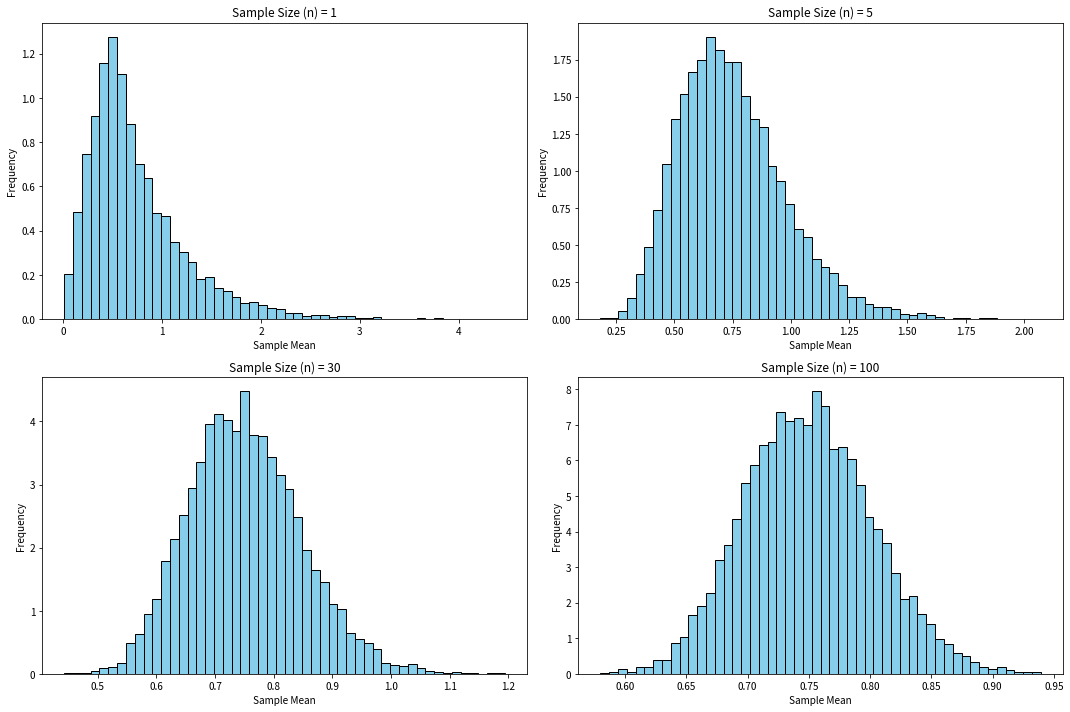

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 为了结果可复现
np.random.seed(42)

def simulate_clt(n_samples, iterations=10000):
    """
    n_samples: 每次抽取的样本量 (n)
    iterations: 模拟实验的次数
    """
    # 模拟两个独立不同分布
    # 1. 指数分布 (lambda=1.0)
    data_a = np.random.exponential(scale=1.0, size=(iterations, n_samples))
    # 2. 均匀分布 (0到1)
    data_b = np.random.uniform(low=0, high=1, size=(iterations, n_samples))
    
    # 将两个分布混合（代表独立变量相加）
    combined_data = (data_a + data_b) / 2
    
    # 计算每次实验的均值
    sample_means = np.mean(combined_data, axis=1)
    
    return sample_means

# 设定不同的样本量进行对比
sample_sizes = [1, 5, 30, 100]
plt.figure(figsize=(15, 10))

for i, n in enumerate(sample_sizes):
    means = simulate_clt(n)
    
    plt.subplot(2, 2, i+1)
    plt.hist(means, bins=50, color='skyblue', edgecolor='black', density=True)
    plt.title(f'Sample Size (n) = {n}')
    plt.xlabel('Sample Mean')
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()